In [ ]:
# Install libraries on the uv venv
!uv add pandas
!uv add numpy
!uv add matplotlib
!uv add folium

# EDA EcoBicis — Septiembre y Octubre 2026 (Bimestral)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from branca.colormap import LinearColormap
from matplotlib.colors import to_hex

from datasetting import DATA_DIR, DIAS, cargar_datos, filtrar_validos, uso_por_estacion, aplicar_estilo

# Estilo de las gráficas: paleta categórica fija y ejes discretos
aplicar_estilo()

## Carga, combinación y limpieza de datos
Se cargan ambos meses (`viajes_ecobici_092026.csv` y `public_data_web_2026-10.csv`) con `validos=False` usando `datasetting.cargar_datos()` y se concatenan en un único DataFrame para revisar calidad y duplicados antes de filtrar.
Los CSV mensuales de Ecobici se particionan por fecha de arribo (`sep` cierra el `30/09` y `oct` abre el `01/10`), por lo que los viajes de la noche del 30 de septiembre quedan completos al unir ambos archivos.

In [2]:
viajes_sep, estaciones = cargar_datos(validos=False, ruta_viajes=DATA_DIR / "viajes_ecobici_092026.csv")
viajes_oct, _ = cargar_datos(validos=False, ruta_viajes=DATA_DIR / "public_data_web_2026-10.csv")

viajes = pd.concat([viajes_sep, viajes_oct], ignore_index=True)
print(f"Septiembre: {len(viajes_sep):,} | Octubre: {len(viajes_oct):,} | Total combinado: {len(viajes):,} viajes, {len(estaciones):,} estaciones")
viajes.head()

Septiembre: 1,498,934 | Octubre: 1,599,384 | Total combinado: 3,098,318 viajes, 677 estaciones


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular,Rango_Edad,Alcaldia_Retiro,Alcaldia_Arribo,Distancia_km,Velocidad_kmh
0,M,30,6583322,28,258,2026-08-31 23:54:59,2026-09-01 00:00:03,5.066667,2026-08-31,23,0,False,False,25-34,Cuauhtemoc,Cuauhtemoc,1.044246,12.366068
1,F,33,4139655,30,530,2026-08-31 23:24:43,2026-09-01 00:00:04,35.350000,2026-08-31,23,0,False,False,25-34,Cuauhtemoc,Azcapotzalco,4.280840,7.265924
2,O,32,6378079,139,559,2026-08-31 23:46:59,2026-09-01 00:00:35,13.600000,2026-08-31,23,0,False,False,25-34,Cuauhtemoc,Cuauhtemoc,2.254665,9.947052
3,M,35,6074272,365,312,2026-08-31 23:52:10,2026-09-01 00:00:44,8.566667,2026-08-31,23,0,False,False,35-44,Benito Juarez,Benito Juarez,1.316417,9.220041
4,M,30,4162376,412,337,2026-08-31 23:51:45,2026-09-01 00:00:55,9.166667,2026-08-31,23,0,False,False,25-34,Benito Juarez,Benito Juarez,1.882482,12.321701


In [3]:
viajes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3098318 entries, 0 to 3098317
Data columns (total 18 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Genero_Usuario         category      
 1   Edad_Usuario           Int64         
 2   Bici                   int64         
 3   Ciclo_Estacion_Retiro  Int64         
 4   Ciclo_Estacion_Arribo  Int64         
 5   Fecha_Hora_Retiro      datetime64[ns]
 6   Fecha_Hora_Arribo      datetime64[ns]
 7   Duracion_min           float64       
 8   Fecha                  datetime64[ns]
 9   Hora                   int32         
 10  Dia_Semana             int32         
 11  Fin_de_Semana          bool          
 12  Viaje_Circular         boolean       
 13  Rango_Edad             category      
 14  Alcaldia_Retiro        object        
 15  Alcaldia_Arribo        object        
 16  Distancia_km           float64       
 17  Velocidad_kmh          float64       
dtypes: Int64(3), bool(1), 

## Catálogo de estaciones
Indexado por `num_cicloe`; la columna `Estacion` es `calle_prin y calle_secu`.

In [4]:
estaciones

,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus,Estacion
num_cicloe,,,,,,,,,
1,Rio Sena,Rio Balsas,Cuauhtemoc,Cuauhtemoc,19.433590,-99.167819,Arroyo,Instalada,Rio Sena y Rio Balsas
2,Rio Guadalquivir,Rio Nazas,Cuauhtemoc,Cuauhtemoc,19.430623,-99.171231,Arroyo,Instalada,Rio Guadalquivir y Rio Nazas
3,Av. Paseo de la Reforma,Av. Insurgentes,Tabacalera,Cuauhtemoc,19.431630,-99.158547,Banqueta,Instalada,Av. Paseo de la Reforma y Av. Insurgentes
4,Rio Nilo,Rio Panuco,Cuauhtemoc,Cuauhtemoc,19.428491,-99.171693,Arroyo,Instalada,Rio Nilo y Rio Panuco
5,Rio Panuco,Rio Tiber,Cuauhtemoc,Cuauhtemoc,19.429804,-99.169451,Arroyo,Instalada,Rio Panuco y Rio Tiber
...,...,...,...,...,...,...,...,...,...
707,Irlanda,Av. Division del Norte,Parque San Andres,Coyoacan,19.348076,-99.149060,Arroyo,Instalada,Irlanda y Av. Division del Norte
708,Irlanda,Canada,Parque San Andres,Coyoacan,19.346489,-99.145828,Arroyo,Instalada,Irlanda y Canada
709,Inglaterra,Antigua Taxque�a,Parque San Andres,Coyoacan,19.344271,-99.149973,Arroyo,Instalada,Inglaterra y Antigua Taxque�a


In [5]:
estaciones.info()

<class 'pandas.core.frame.DataFrame'>
Index: 677 entries, 1 to 711
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   calle_prin  677 non-null    object 
 1   calle_secu  677 non-null    object 
 2   colonia     677 non-null    object 
 3   alcaldia    677 non-null    object 
 4   latitud     677 non-null    float64
 5   longitud    677 non-null    float64
 6   sitio_de_e  677 non-null    object 
 7   estatus     677 non-null    object 
 8   Estacion    677 non-null    object 
dtypes: float64(2), object(7)
memory usage: 69.7+ KB


## Variables derivadas
Ya vienen calculadas desde `datasetting.agregar_columnas`: duración, fecha, hora, día de la semana, fin de semana, viajes circulares (misma estación de retiro y arribo), rango de edad, alcaldías de origen y destino, distancia y velocidad.

In [6]:
cols_derivadas = ["Duracion_min", "Fecha", "Hora", "Dia_Semana", "Fin_de_Semana", "Viaje_Circular",
                  "Rango_Edad", "Alcaldia_Retiro", "Alcaldia_Arribo", "Distancia_km", "Velocidad_kmh"]
viajes[cols_derivadas].head()

,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular,Rango_Edad,Alcaldia_Retiro,Alcaldia_Arribo,Distancia_km,Velocidad_kmh
0,5.066667,2026-08-31,23,0,False,False,25-34,Cuauhtemoc,Cuauhtemoc,1.044246,12.366068
1,35.350000,2026-08-31,23,0,False,False,25-34,Cuauhtemoc,Azcapotzalco,4.280840,7.265924
2,13.600000,2026-08-31,23,0,False,False,25-34,Cuauhtemoc,Cuauhtemoc,2.254665,9.947052
3,8.566667,2026-08-31,23,0,False,False,35-44,Benito Juarez,Benito Juarez,1.316417,9.220041
4,9.166667,2026-08-31,23,0,False,False,25-34,Benito Juarez,Benito Juarez,1.882482,12.321701


In [7]:
viajes.describe()

,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Distancia_km,Velocidad_kmh
count,3098259.0,3.098318e+06,3098318.0,3098318.0,3098318,3098318,3.098318e+06,3098318,3.098318e+06,3.098318e+06,3.098318e+06,3.098318e+06
mean,34.818767,5.481749e+06,294.521895,292.344902,2026-10-01 23:48:11.674655488,2026-10-02 00:04:06.846956032,1.591954e+01,2026-10-01 09:32:11.997682432,1.377112e+01,2.730132e+00,1.860081e+00,8.145134e+00
min,16.0,2.000461e+06,1.0,1.0,2026-02-10 08:46:10,2026-09-01 00:00:03,2.666667e-01,2026-02-10 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,28.0,3.745411e+06,115.0,111.0,2026-09-17 06:11:05.500000,2026-09-17 06:21:58.249999872,7.183333e+00,2026-09-17 00:00:00,1.000000e+01,1.000000e+00,8.697077e-01,6.471777e+00
50%,33.0,5.502869e+06,257.0,256.0,2026-10-01 20:07:01,2026-10-01 20:22:41,1.203333e+01,2026-10-01 00:00:00,1.400000e+01,3.000000e+00,1.475467e+00,8.448100e+00
75%,40.0,7.227879e+06,481.0,483.0,2026-10-17 10:38:39.750000128,2026-10-17 10:53:33.750000128,2.013333e+01,2026-10-17 00:00:00,1.800000e+01,4.000000e+00,2.489111e+00,1.023415e+01
max,130.0,8.999708e+06,711.0,711.0,2026-10-31 23:56:08,2026-10-31 23:59:54,3.514386e+05,2026-10-31 00:00:00,2.300000e+01,6.000000e+00,1.359759e+01,2.833328e+01
std,9.934608,2.022954e+06,208.362632,209.523354,NaN,NaN,3.120188e+02,NaN,4.676274e+00,1.858963e+00,1.399999e+00,3.211217e+00


## Calidad de los datos (Septiembre + Octubre)

In [8]:
dur = viajes["Duracion_min"]

print("=" * 42)
print("Nulos por columna:")
print(viajes.isna().sum()[lambda s: s > 0])
print("=" * 42)

print("Filas duplicadas:", viajes.duplicated().sum())
print("Géneros:", viajes["Genero_Usuario"].value_counts().to_dict())

print(f"Duración < 1 min: {(dur < 1).sum():>6}")
print(f"Duración > 3 h:   {(dur > 180).sum():>6}")
print(f"Duración > 24 h:  {(dur > 1440).sum():>6}   (max: {dur.max() / 1440:.0f} días)")
print(f"Retiros antes de septiembre: {(viajes['Fecha_Hora_Retiro'] < '2026-09-01').sum()}")

Nulos por columna:
Edad_Usuario    59
Rango_Edad      65
dtype: int64
Filas duplicadas: 0
Géneros: {'M': 2104304, 'F': 860766, '?': 78631, 'O': 54617}
Duración < 1 min:    447
Duración > 3 h:     1385
Duración > 24 h:      61   (max: 244 días)
Retiros antes de septiembre: 103


In [9]:
ids_catalogo = set(estaciones.index)
ids_viajes = set(viajes["Ciclo_Estacion_Retiro"]) | set(viajes["Ciclo_Estacion_Arribo"])

print("Estaciones en viajes que no están en el catálogo:", sorted(ids_viajes - ids_catalogo))
print("Estaciones (num) del catálogo sin ningún viaje:", sorted(ids_catalogo - ids_viajes))

# El CSV de estaciones trae ñ y acentos perdidos, guardados como "�"
cols_texto = ["calle_prin", "calle_secu", "colonia", "alcaldia", "sitio_de_e"]
con_error = estaciones[cols_texto].apply(lambda col: col.str.contains("�", regex=False)).any(axis=1)
print("Filas del catálogo con caracteres perdidos (�):", con_error.sum())
estaciones.loc[con_error, cols_texto].head()

Estaciones en viajes que no están en el catálogo: []
Estaciones (num) del catálogo sin ningún viaje: [np.int64(699)]
Filas del catálogo con caracteres perdidos (�): 34


,calle_prin,calle_secu,colonia,alcaldia,sitio_de_e
num_cicloe,,,,,
54,Parque Espa�a,Sonora,Condesa,Cuauhtemoc,Arroyo
58,Parque Espa�a,Juan de la Barrera,Condesa,Cuauhtemoc,Banqueta
83,Alfonso Reyes,Nuevo Le�n,Hipodromo,Cuauhtemoc,Arroyo
97,Republica de Salvador,Jose Maria Pino Suarez,Centro,Cuauhtemoc,Camell�n
134,Alvaro Obregon,Orizaba,Roma Norte,Cuauhtemoc,Camell�n


**Hallazgos**
- `0` filas duplicadas al combinar septiembre y octubre.
- 61 viajes duran más de 24 h (el más largo ~244 días, con retiros desde febrero): bicis no devueltas o errores de registro.
- 447 viajes duran menos de 1 min: probablemente retiros cancelados.
- 103 viajes tienen retiro antes del 1 de septiembre (principalmente noche del 31 de agosto).
- 78,631 viajes tienen género `?` (sin dato), 59 no tienen edad y 6 registran edad `130` (fuera de los rangos `16-100`).
- Todas las estaciones de los viajes existen en el catálogo; la 699 no tiene viajes en ninguno de los dos meses.
- 34 estaciones tienen ñ/acentos perdidos (`La Coru�a`).

Para el resto del análisis se usan los viajes retirados entre el 1 de septiembre y el 31 de octubre con duración entre 1 min y 3 h.

### Viajes válidos (Sep–Oct)

In [10]:
# Viajes válidos (entre 1 min y 3 horas, del 1 de sept al 31 de oct 2026).
viajes_validos = filtrar_validos(viajes, desde="2026-09-01", hasta="2026-11-01")
viajes_validos["Mes"] = viajes_validos["Fecha_Hora_Retiro"].dt.strftime("%Y-%m")

print("Viajes válidos:")
print(f"{len(viajes_validos):,} de {len(viajes):,} viajes ({len(viajes_validos) / len(viajes):.2%})")

# Resumen comparativo mensual
resumen_mes = viajes_validos.groupby("Mes").agg(
    Viajes=("Bici", "size"),
    Dias=("Fecha", "nunique"),
    Duracion_Mediana=("Duracion_min", "median"),
    Distancia_Media_km=("Distancia_km", "mean"),
)
resumen_mes["Viajes_por_Dia"] = (resumen_mes["Viajes"] / resumen_mes["Dias"]).round(0)
resumen_mes.round(2)

Viajes válidos:
3,096,404 de 3,098,318 viajes (99.94%)


,Viajes,Dias,Duracion_Mediana,Distancia_Media_km,Viajes_por_Dia
Mes,,,,,
2026-09,1498235,30,11.80,1.85,49941.0
2026-10,1598169,31,12.23,1.87,51554.0


## Perfil de usuarios

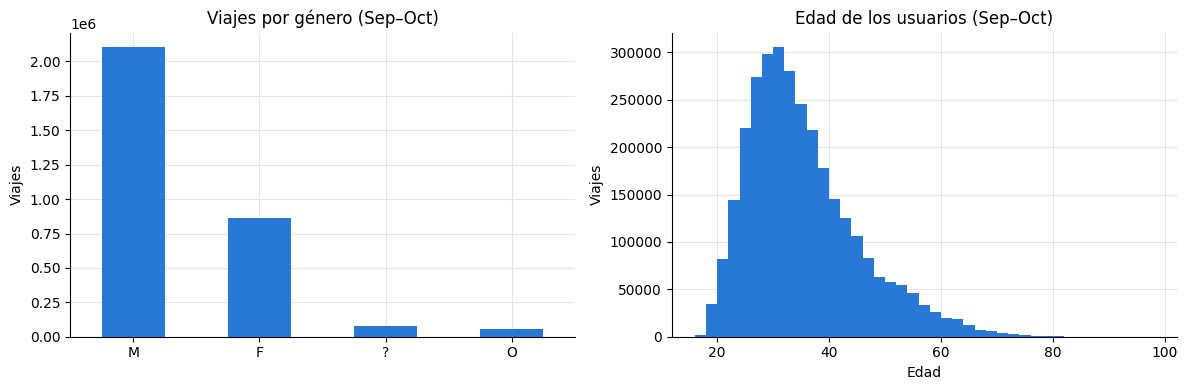

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

viajes_validos["Genero_Usuario"].value_counts().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Viajes por género (Sep–Oct)", xlabel="", ylabel="Viajes")

viajes_validos["Edad_Usuario"].plot.hist(bins=range(16, 100, 2), ax=axes[1])
axes[1].set(title="Edad de los usuarios (Sep–Oct)", xlabel="Edad", ylabel="Viajes")

plt.tight_layout()
plt.show()

In [12]:
rango_edad = pd.cut(
    viajes_validos["Edad_Usuario"],
    bins=[15, 24, 34, 44, 54, 64, 100],
    labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)
# Proporción de cada rango de edad dentro de cada género
pd.crosstab(rango_edad, viajes_validos["Genero_Usuario"], normalize="columns").round(3)

Genero_Usuario,?,F,M,O
Edad_Usuario,,,,
16-24,0.157,0.123,0.114,0.097
25-34,0.551,0.508,0.428,0.494
35-44,0.211,0.244,0.283,0.305
45-54,0.057,0.088,0.118,0.079
55-64,0.021,0.031,0.046,0.020
65+,0.003,0.006,0.012,0.003


## Patrones temporales
Los promedios se dividen entre el número de días de cada tipo en el bimestre (61 días totales: 44 entre semana y 17 de fin de semana).

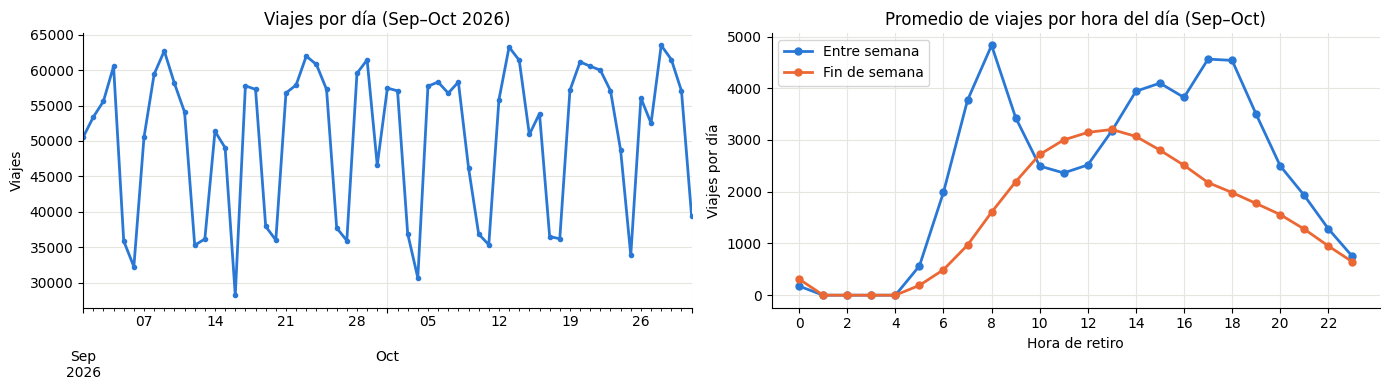

In [13]:
dias_por_tipo = viajes_validos.groupby("Fin_de_Semana")["Fecha"].nunique()
# Ecobici no opera de 1:00 a 4:59, así que esas horas se rellenan con 0
por_hora = viajes_validos.groupby(["Hora", "Fin_de_Semana"]).size().unstack().reindex(range(24), fill_value=0) / dias_por_tipo
por_hora.columns = ["Entre semana", "Fin de semana"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

viajes_validos.groupby("Fecha").size().plot(ax=axes[0], marker="o", markersize=3)
axes[0].set(title="Viajes por día (Sep–Oct 2026)", xlabel="", ylabel="Viajes")

por_hora.plot(ax=axes[1], marker="o")
axes[1].set(title="Promedio de viajes por hora del día (Sep–Oct)", xlabel="Hora de retiro", ylabel="Viajes por día")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

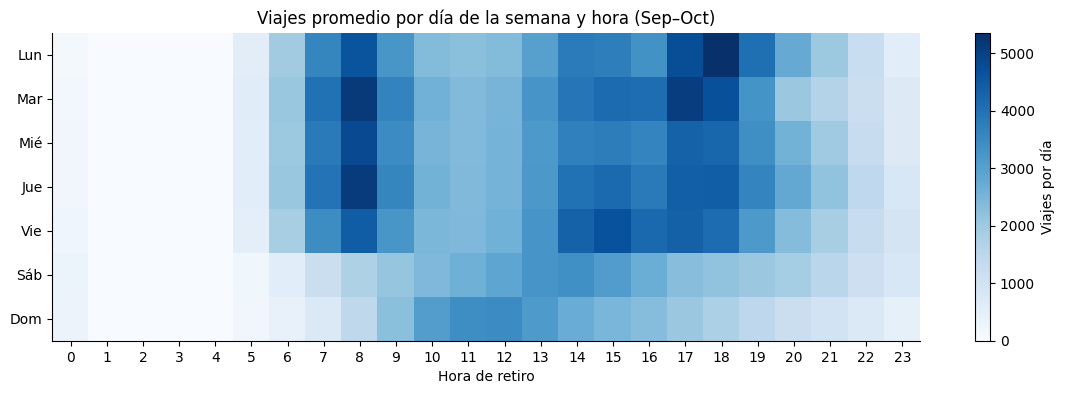

In [14]:
dias_por_semana = viajes_validos.groupby("Dia_Semana")["Fecha"].nunique()
calor = (pd.crosstab(viajes_validos["Dia_Semana"], viajes_validos["Hora"])
         .reindex(columns=range(24), fill_value=0)
         .div(dias_por_semana, axis=0))

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(calor, cmap="Blues", aspect="auto")
ax.set_yticks(range(7), DIAS)
ax.set_xticks(range(24))
ax.grid(False)
ax.set(title="Viajes promedio por día de la semana y hora (Sep–Oct)", xlabel="Hora de retiro")
fig.colorbar(im, ax=ax, label="Viajes por día")
plt.show()

## Duración de los viajes

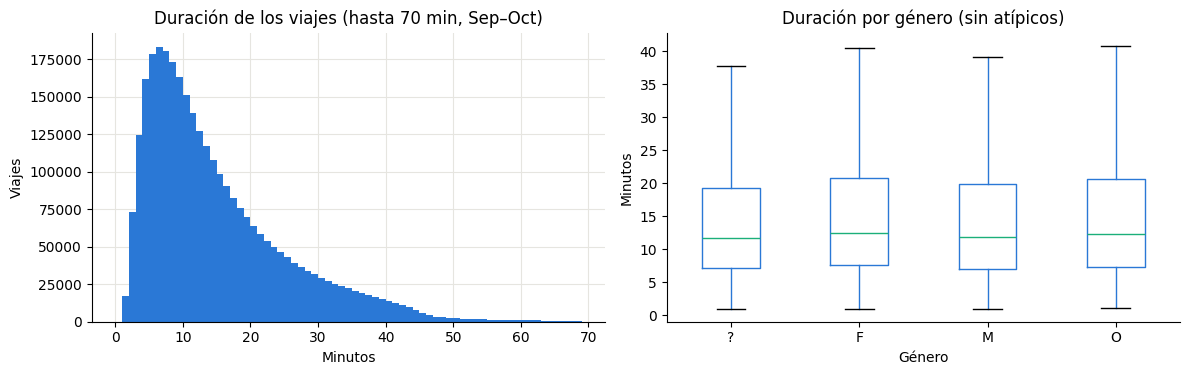

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

viajes_validos["Duracion_min"].plot.hist(bins=range(0, 70), ax=axes[0])
axes[0].set(title="Duración de los viajes (hasta 70 min, Sep–Oct)", xlabel="Minutos", ylabel="Viajes")

viajes_validos.boxplot(column="Duracion_min", by="Genero_Usuario", ax=axes[1], showfliers=False, grid=False)
axes[1].set(title="Duración por género (sin atípicos)", xlabel="Género", ylabel="Minutos")
fig.suptitle("")

plt.tight_layout()
plt.show()

In [16]:
(viajes_validos.groupby("Fin_de_Semana")["Duracion_min"]
    .describe(percentiles=[0.5, 0.9]).round(1)
    .rename(index={False: "Entre semana", True: "Fin de semana"}))

,count,mean,std,min,50%,90%,max
Fin_de_Semana,,,,,,,
Entre semana,2474570.0,14.8,10.9,1.0,11.8,29.2,180.0
Fin de semana,621834.0,17.3,14.2,1.0,13.1,35.5,179.5


## Estaciones
`Neto` = arribos − retiros. Negativo: la estación se vacía; positivo: se llena (candidatas a rebalanceo).

In [17]:
nombre_estacion = estaciones["Estacion"]

uso = uso_por_estacion(viajes_validos, estaciones)

print(f"Viajes circulares (misma estación): {viajes_validos['Viaje_Circular'].mean():.2%}")
uso.sort_values("Total", ascending=False).head(10)

Viajes circulares (misma estación): 2.72%


,Estacion,Retiros,Arribos,Total,Neto
num_cicloe,,,,,
271,Jesus Garcia y Carlos J. Meneses,22266,35179,57445,12913
548,Doctor Mariano Azuela y Jose Antonio Alzate,18076,19887,37963,1811
27,Av. Paseo de la Reforma y Havre,16864,17320,34184,456
38,Cozumel y Puebla,16286,16105,32391,-181
64,Sonora y Amsterdam,15068,16426,31494,1358
555,Av. Ribera de San Cosme y Av. Insurgentes Centro,15213,14375,29588,-838
208,Hesiodo y Lamartine,15545,13422,28967,-2123
43,Juarez y Doctor Mora,13692,14902,28594,1210
14,Av. Paseo de la Reforma y Rio de la Plata,13098,15336,28434,2238


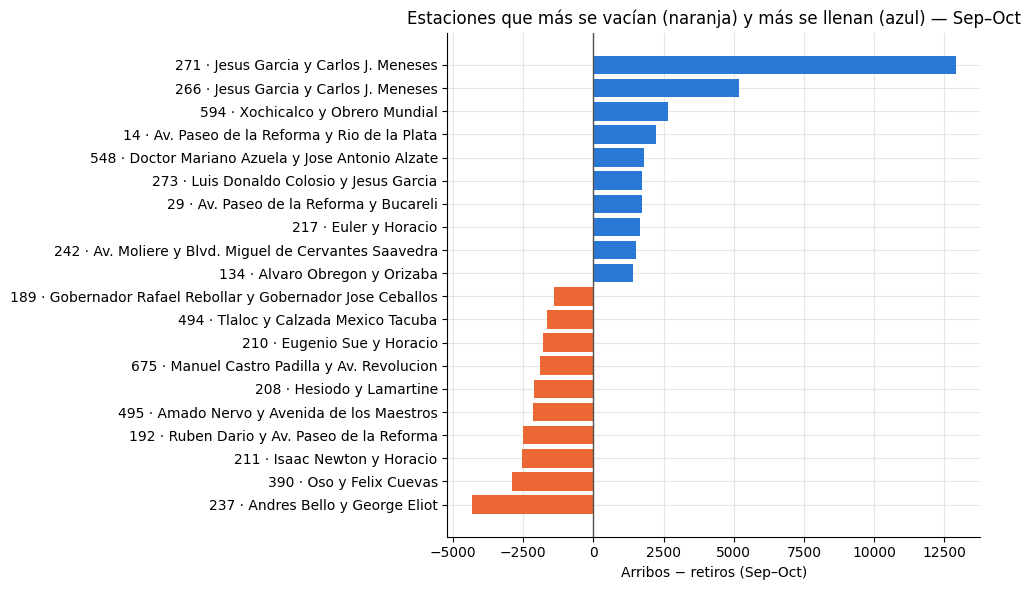

In [18]:
extremos = pd.concat([uso.nsmallest(10, "Neto"), uso.nlargest(10, "Neto")]).sort_values("Neto")
etiquetas = [f"{i} · {n}" for i, n in zip(extremos.index, extremos["Estacion"])]
colores = np.where(extremos["Neto"] < 0, "#eb6834", "#2a78d6")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(etiquetas, extremos["Neto"], color=colores)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Estaciones que más se vacían (naranja) y más se llenan (azul) — Sep–Oct", xlabel="Arribos − retiros (Sep–Oct)")
plt.tight_layout()
plt.show()

In [19]:
rutas = (
    viajes_validos[~viajes_validos["Viaje_Circular"]]
    .groupby(["Ciclo_Estacion_Retiro", "Ciclo_Estacion_Arribo"]).size()
    .nlargest(15).rename("Viajes").reset_index()
)
rutas["Origen"] = rutas["Ciclo_Estacion_Retiro"].map(nombre_estacion)
rutas["Destino"] = rutas["Ciclo_Estacion_Arribo"].map(nombre_estacion)
rutas

,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Viajes,Origen,Destino
0,621,618,1544,Lago Poniente y Calzada de Tlalpan,Bartolome R. Salido y Edzna
1,548,498,1248,Doctor Mariano Azuela y Jose Antonio Alzate,Avenida de los Maestros y Plan de Agua Prieta
2,494,486,1205,Tlaloc y Calzada Mexico Tacuba,Izcoatl y Circuito Interior Melchor Ocampo
3,495,499,1171,Amado Nervo y Avenida de los Maestros,Avenida de los Maestros y Calzada de los Gallos
4,618,621,1160,Bartolome R. Salido y Edzna,Lago Poniente y Calzada de Tlalpan
5,495,498,1095,Amado Nervo y Avenida de los Maestros,Avenida de los Maestros y Plan de Agua Prieta
6,593,595,1017,Zempoala y Diagonal de San Antonio,Yacatas y Diagonal de San Antonio
7,237,235,1011,Andres Bello y George Eliot,Campos Eliseos y Av. Moliere
8,498,548,987,Avenida de los Maestros y Plan de Agua Prieta,Doctor Mariano Azuela y Jose Antonio Alzate
9,539,548,978,Naranjo y Av. Ricardo Flores Mag�n,Doctor Mariano Azuela y Jose Antonio Alzate


## Análisis geográfico
La distancia es en línea recta entre estaciones (cota inferior de la distancia real recorrida).

In [20]:
coords = estaciones
mapa = coords.join(uso["Total"]).fillna({"Total": 0})


def mapa_estaciones(mapa, titulo, log=False):
    """Mapa interactivo (zoom, arrastre, hover) de las estaciones sobre un mapa de calles."""
    mapa = mapa.reset_index()
    mapa["Estacion"] = mapa["calle_prin"] + " y " + mapa["calle_secu"]
    sin_viajes = mapa[mapa["Total"] == 0]
    con_viajes = mapa[mapa["Total"] > 0].sort_values("Total")

    valor = np.log10(con_viajes["Total"]) if log else con_viajes["Total"]
    azules = [to_hex(c) for c in plt.cm.Blues(np.linspace(0.35, 1, 6))]
    escala = LinearColormap(azules, vmin=valor.min(), vmax=valor.max(),
                            caption="Retiros + arribos, log10 (1 = 10, 2 = 100, 3 = 1,000)" if log else "Retiros + arribos")

    fig = folium.Figure(height=700)
    m = folium.Map(tiles="OpenStreetMap", zoom_snap=0.25).add_to(fig)
    m.fit_bounds([[mapa["latitud"].min(), mapa["longitud"].min()], [mapa["latitud"].max(), mapa["longitud"].max()]])

    for fila, v in zip(con_viajes.itertuples(), valor):
        folium.CircleMarker(
            [fila.latitud, fila.longitud], radius=4, weight=0.5, color="#52514e",
            fill=True, fill_color=escala(v), fill_opacity=0.9,
            tooltip=f"<b>{fila.Estacion}</b><br>Estación {fila.num_cicloe} · {fila.colonia}, {fila.alcaldia}"
                    f"<br>Retiros + arribos: {fila.Total:,.0f}",
        ).add_to(m)
    for fila in sin_viajes.itertuples():
        folium.CircleMarker(
            [fila.latitud, fila.longitud], radius=3, weight=1, color="#8a8984", fill=False,
            tooltip=f"<b>{fila.Estacion}</b><br>Estación {fila.num_cicloe} · Sin viajes",
        ).add_to(m)

    escala.add_to(m)
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:absolute; top:10px; left:55px; z-index:1000; background:white; padding:4px 10px;'
        f' border-radius:4px; box-shadow:0 1px 4px rgba(0,0,0,.3); font:14px sans-serif">{titulo}</div>'))
    return fig


mapa_estaciones(mapa, "Estaciones Ecobici por número de viajes (Sep–Oct)")

#### Domingos: Análisis geográfico

In [21]:
viajes_validos_dom = viajes_validos[viajes_validos["Dia_Semana"] == 6]

uso_dom = uso_por_estacion(viajes_validos_dom, estaciones)
mapa_dom = coords.join(uso_dom["Total"]).fillna({"Total": 0})

# Escala logarítmica: unas pocas estaciones concentran muchos viajes en domingo
mapa_estaciones(mapa_dom, "Estaciones Ecobici por número de viajes (domingos de Sep–Oct)", log=True)

In [22]:
# Distancia_km y Velocidad_kmh ya vienen calculadas (ver datasetting.haversine_km)
no_circulares = viajes_validos[~viajes_validos["Viaje_Circular"]]
print(f"Viajes a más de 30 km/h (sospechosos): {(no_circulares['Velocidad_kmh'] > 30).sum()}")
no_circulares[["Distancia_km", "Velocidad_kmh"]].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(2)

Viajes a más de 30 km/h (sospechosos): 0


,Distancia_km,Velocidad_kmh
count,3012067.00,3012067.00
mean,1.91,8.38
std,1.38,2.94
min,0.00,0.00
5%,0.45,2.83
50%,1.51,8.54
95%,4.72,12.94
99%,6.56,15.01
max,13.60,28.33


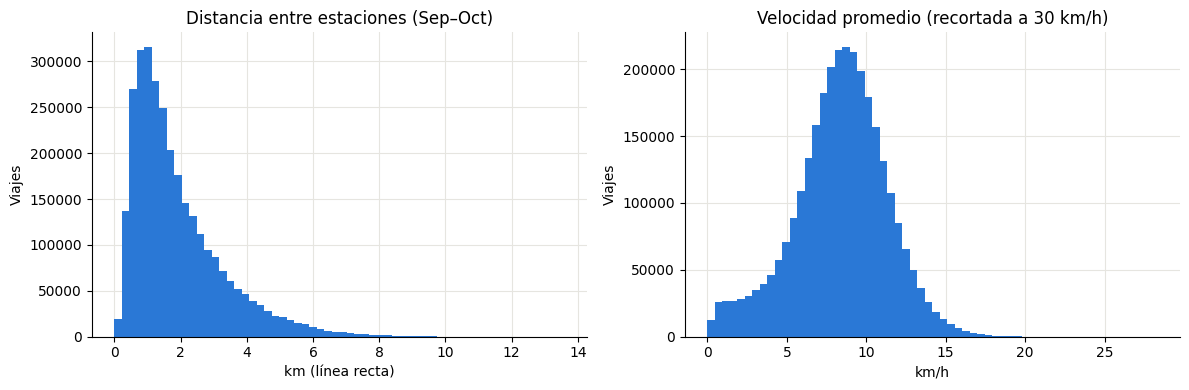

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

no_circulares["Distancia_km"].plot.hist(bins=60, ax=axes[0])
axes[0].set(title="Distancia entre estaciones (Sep–Oct)", xlabel="km (línea recta)", ylabel="Viajes")

no_circulares["Velocidad_kmh"].clip(upper=30).plot.hist(bins=60, ax=axes[1])
axes[1].set(title="Velocidad promedio (recortada a 30 km/h)", xlabel="km/h", ylabel="Viajes")

plt.tight_layout()
plt.show()

In [24]:
por_alcaldia = pd.DataFrame({
    "Estaciones": estaciones["alcaldia"].value_counts(),
    "Retiros": viajes_validos["Alcaldia_Retiro"].value_counts(),
})
por_alcaldia["Retiros_por_estacion"] = (por_alcaldia["Retiros"] / por_alcaldia["Estaciones"]).round(0)
por_alcaldia.sort_values("Retiros", ascending=False)

,Estaciones,Retiros,Retiros_por_estacion
Cuauhtemoc,243,1511646,6221.0
Benito Juarez,213,743573,3491.0
Miguel Hidalgo,139,660690,4753.0
Coyoacan,37,74488,2013.0
Azcapotzalco,28,63044,2252.0
Alvaro Obregon,17,42963,2527.0


In [25]:
# Proporción de destinos para cada alcaldía de origen
pd.crosstab(
    viajes_validos["Alcaldia_Retiro"].rename("Origen"),
    viajes_validos["Alcaldia_Arribo"].rename("Destino"),
    normalize="index",
).round(3)

Destino,Alvaro Obregon,Azcapotzalco,Benito Juarez,Coyoacan,Cuauhtemoc,Miguel Hidalgo
Origen,,,,,,
Alvaro Obregon,0.332,0.000,0.391,0.165,0.090,0.022
Azcapotzalco,0.000,0.466,0.005,0.000,0.182,0.348
Benito Juarez,0.021,0.000,0.741,0.038,0.160,0.040
Coyoacan,0.067,0.000,0.324,0.567,0.034,0.008
Cuauhtemoc,0.001,0.008,0.069,0.002,0.793,0.127
Miguel Hidalgo,0.001,0.035,0.048,0.001,0.350,0.564


## Uso de las bicicletas

Bicis distintas en Sep–Oct: 6,581


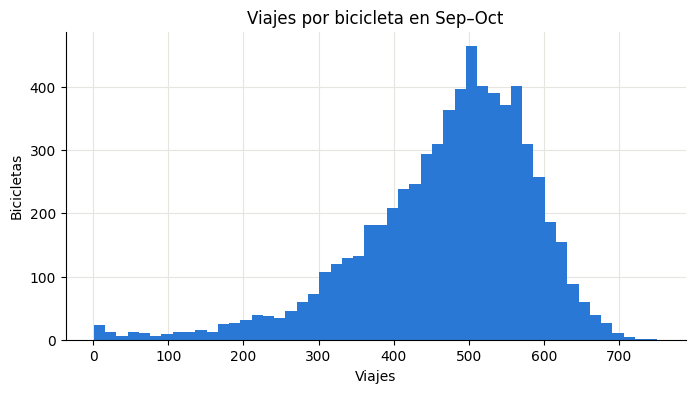

count    6581.0
mean      470.5
std       115.0
min         1.0
25%       411.0
50%       491.0
75%       551.0
max       751.0
Name: count, dtype: float64

In [26]:
viajes_por_bici = viajes_validos["Bici"].value_counts()
print(f"Bicis distintas en Sep–Oct: {viajes_por_bici.size:,}")

fig, ax = plt.subplots(figsize=(8, 4))
viajes_por_bici.plot.hist(bins=50, ax=ax)
ax.set(title="Viajes por bicicleta en Sep–Oct", xlabel="Viajes", ylabel="Bicicletas")
plt.show()

viajes_por_bici.describe().round(1)

## Hotspots críticos de carga: $L(B) \to 0$ (casi vacía) y $L(B) \to 1$ (casi llena)
De acuerdo con la definición:
$$L(B) = \frac{k}{C}$$
donde $k$ es el número de bicicletas en la estación y $C$ es su capacidad en puertos, una estación es **crítica** cuando $L(B) \to 0$ (riesgo de vaciamiento) o $L(B) \to 1$ (riesgo de saturación).

> **Nota sobre los datos:** ni `estaciones_ecobici.csv` ni los CSV de viajes incluyen la capacidad $C$ de cada estación ni el inventario en tiempo real $k$ (tampoco los movimientos de camión de rebalanceo). Por ello, identificamos los **hotspots que empujan $L(B)$ hacia $0$ o hacia $1$** mediante:
1. **Flujo neto diario (`Neto_Dia`)** y **desbalance relativo (`Desbalance_Rel = Neto / Total`)**: estaciones con pérdida o acumulación sistemática de bicicletas cada día.
2. **Oscilación intradía entre semana (`Oscilacion_Sem_Dia`)**: amplitud máxima acumulada (`max(cum_net) - min(cum_net)`) a lo largo de las 24 h de un día hábil promedio. Mide cuántas bicis fluctúan en un solo día (y equivale a la capacidad mínima $C$ necesaria para absorber la marea diaria sin tocar $L(B)=0$ ni $L(B)=1$).

TOP 10 HOTSPOTS CON TENDENCIA A VACIARSE -> L(B) -> 0 (mayor deficit neto diario):

TOP 10 HOTSPOTS CON TENDENCIA A LLENARSE -> L(B) -> 1 (mayor superavit neto diario):

TOP 10 HOTSPOTS POR OSCILACION INTRADIA (riesgo de L->0 y L->1 en distintas horas del dia):


,Estacion,Alcaldia,Total_Dia,Neto_Dia,Desbalance_Rel,Oscilacion_Sem_Dia
num_cicloe,,,,,,
237,Andres Bello y George Eliot,Miguel Hidalgo,438.7,-71.11,-0.162,93.30
390,Oso y Felix Cuevas,Benito Juarez,319.2,-47.28,-0.148,60.95
211,Isaac Newton y Horacio,Miguel Hidalgo,211.8,-41.56,-0.196,57.36
192,Ruben Dario y Av. Paseo de la Reforma,Miguel Hidalgo,353.2,-41.00,-0.116,57.64
495,Amado Nervo y Avenida de los Maestros,Miguel Hidalgo,319.3,-35.26,-0.110,43.84
208,Hesiodo y Lamartine,Miguel Hidalgo,474.9,-34.80,-0.073,75.36
675,Manuel Castro Padilla y Av. Revolucion,Alvaro Obregon,217.8,-31.38,-0.144,41.41
210,Eugenio Sue y Horacio,Miguel Hidalgo,128.8,-29.25,-0.227,36.70
494,Tlaloc y Calzada Mexico Tacuba,Miguel Hidalgo,393.1,-26.93,-0.069,34.32


,Estacion,Alcaldia,Total_Dia,Neto_Dia,Desbalance_Rel,Oscilacion_Sem_Dia
num_cicloe,,,,,,
271,Jesus Garcia y Carlos J. Meneses,Cuauhtemoc,941.7,211.69,0.225,519.05
266,Jesus Garcia y Carlos J. Meneses,Cuauhtemoc,422.2,84.95,0.201,217.64
594,Xochicalco y Obrero Mundial,Benito Juarez,238.8,43.43,0.182,50.95
14,Av. Paseo de la Reforma y Rio de la Plata,Cuauhtemoc,466.1,36.69,0.079,108.43
548,Doctor Mariano Azuela y Jose Antonio Alzate,Cuauhtemoc,622.3,29.69,0.048,95.77
273,Luis Donaldo Colosio y Jesus Garcia,Cuauhtemoc,320.5,28.43,0.089,142.43
29,Av. Paseo de la Reforma y Bucareli,Cuauhtemoc,387.8,28.25,0.073,36.50
217,Euler y Horacio,Miguel Hidalgo,298.3,27.15,0.091,72.16
242,Av. Moliere y Blvd. Miguel de Cervantes Saavedra,Miguel Hidalgo,370.1,24.64,0.067,76.66


,Estacion,Alcaldia,Total_Dia,Neto_Dia,Desbalance_Rel,Oscilacion_Sem_Dia
num_cicloe,,,,,,
271,Jesus Garcia y Carlos J. Meneses,Cuauhtemoc,941.7,211.69,0.225,519.05
266,Jesus Garcia y Carlos J. Meneses,Cuauhtemoc,422.2,84.95,0.201,217.64
273,Luis Donaldo Colosio y Jesus Garcia,Cuauhtemoc,320.5,28.43,0.089,142.43
14,Av. Paseo de la Reforma y Rio de la Plata,Cuauhtemoc,466.1,36.69,0.079,108.43
548,Doctor Mariano Azuela y Jose Antonio Alzate,Cuauhtemoc,622.3,29.69,0.048,95.77
237,Andres Bello y George Eliot,Miguel Hidalgo,438.7,-71.11,-0.162,93.30
18,Av. Paseo de la Reforma y Rio Rhin,Cuauhtemoc,453.0,16.16,0.036,81.61
242,Av. Moliere y Blvd. Miguel de Cervantes Saavedra,Miguel Hidalgo,370.1,24.64,0.067,76.66
208,Hesiodo y Lamartine,Miguel Hidalgo,474.9,-34.80,-0.073,75.36


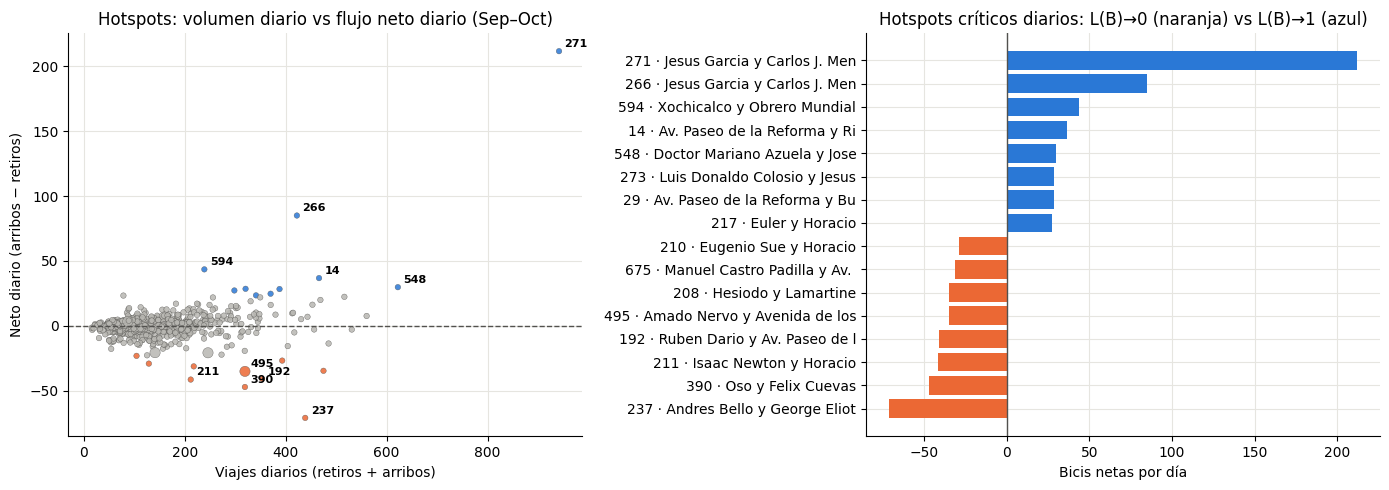

In [27]:
# === HOTSPOTS QUE PROVOCAN L(B) -> 0 (VACIAMIENTO) Y L(B) -> 1 (SATURACION) ===
n_dias = viajes_validos["Fecha"].nunique()
sem = viajes_validos[~viajes_validos["Fin_de_Semana"]]
n_sem = sem["Fecha"].nunique()

hotspots = uso.copy()
hotspots["Retiros_Dia"] = (hotspots["Retiros"] / n_dias).round(1)
hotspots["Arribos_Dia"] = (hotspots["Arribos"] / n_dias).round(1)
hotspots["Total_Dia"] = (hotspots["Total"] / n_dias).round(1)
hotspots["Neto_Dia"] = (hotspots["Neto"] / n_dias).round(2)
hotspots["Desbalance_Rel"] = (hotspots["Neto"] / hotspots["Total"]).round(3)

# Curva horaria neta promedio en dias habiles: detecta estaciones con fuerte marea intradia
ret_h = sem.groupby(["Ciclo_Estacion_Retiro", "Hora"]).size().unstack(fill_value=0)
arr_h = sem.groupby(["Ciclo_Estacion_Arribo", "Hora"]).size().unstack(fill_value=0)
net_h = (
    arr_h.reindex(index=hotspots.index, columns=range(24), fill_value=0)
    - ret_h.reindex(index=hotspots.index, columns=range(24), fill_value=0)
) / n_sem
cum_h = net_h.cumsum(axis=1)
hotspots["Oscilacion_Sem_Dia"] = (cum_h.max(axis=1) - cum_h.min(axis=1)).round(2)
hotspots["Alcaldia"] = hotspots.index.map(estaciones["alcaldia"])
hotspots["Colonia"] = hotspots.index.map(estaciones["colonia"])

# Si luego se incorpora la capacidad C por estacion (ej. GBFS), basta calcular:
# hotspots["Delta_L_Diario"] = hotspots["Neto_Dia"] / hotspots["Capacidad_C"]
# hotspots["Delta_L_Intradia"] = hotspots["Oscilacion_Sem_Dia"] / hotspots["Capacidad_C"]

cols_vista = ["Estacion", "Alcaldia", "Total_Dia", "Neto_Dia", "Desbalance_Rel", "Oscilacion_Sem_Dia"]

print("TOP 10 HOTSPOTS CON TENDENCIA A VACIARSE -> L(B) -> 0 (mayor deficit neto diario):")
display(hotspots.nsmallest(10, "Neto_Dia")[cols_vista])

print("\nTOP 10 HOTSPOTS CON TENDENCIA A LLENARSE -> L(B) -> 1 (mayor superavit neto diario):")
display(hotspots.nlargest(10, "Neto_Dia")[cols_vista])

print("\nTOP 10 HOTSPOTS POR OSCILACION INTRADIA (riesgo de L->0 y L->1 en distintas horas del dia):")
display(hotspots.nlargest(10, "Oscilacion_Sem_Dia")[cols_vista])

# Visualizacion: volumen diario vs desbalance neto diario
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

norm_net = hotspots["Neto_Dia"]
top_vacio = hotspots.nsmallest(10, "Neto_Dia").index
top_lleno = hotspots.nlargest(10, "Neto_Dia").index
colores_pts = np.where(
    hotspots.index.isin(top_vacio), "#eb6834",
    np.where(hotspots.index.isin(top_lleno), "#2a78d6", "#b8b7b2")
)
sizes = np.where(hotspots.index.isin(top_vacio | top_lleno), 55, 16)

axes[0].scatter(hotspots["Total_Dia"], hotspots["Neto_Dia"], c=colores_pts, s=sizes, alpha=0.85, edgecolors="#52514e", linewidths=0.3)
axes[0].axhline(0, color="#52514e", linewidth=1, linestyle="--")
for est_id in list(top_vacio[:5]) + list(top_lleno[:5]):
    row = hotspots.loc[est_id]
    axes[0].annotate(str(est_id), (row["Total_Dia"], row["Neto_Dia"]), xytext=(4, 3), textcoords="offset points", fontsize=8, fontweight="bold")
axes[0].set(title="Hotspots: volumen diario vs flujo neto diario (Sep–Oct)", xlabel="Viajes diarios (retiros + arribos)", ylabel="Neto diario (arribos − retiros)")

# Mapa interactivo de los 30 hotspots criticos (15 L->0 + 15 L->1)
crit_vacio = hotspots.nsmallest(15, "Neto_Dia")
crit_lleno = hotspots.nlargest(15, "Neto_Dia")
ext_h = pd.concat([crit_vacio.head(8), crit_lleno.head(8)]).sort_values("Neto_Dia")
etq_h = [f"{i} · {n[:28]}" for i, n in zip(ext_h.index, ext_h["Estacion"])]
col_h = np.where(ext_h["Neto_Dia"] < 0, "#eb6834", "#2a78d6")
axes[1].barh(etq_h, ext_h["Neto_Dia"], color=col_h)
axes[1].axvline(0, color="#52514e", linewidth=1)
axes[1].set(title="Hotspots críticos diarios: L(B)→0 (naranja) vs L(B)→1 (azul)", xlabel="Bicis netas por día")

plt.tight_layout()
plt.show()

# Mapa geografico de los hotspots (Top 15 vaciamiento en naranja, Top 15 llenado en azul)
fig_m = folium.Figure(height=550)
m_hot = folium.Map(tiles="OpenStreetMap", zoom_snap=0.25).add_to(fig_m)
m_hot.fit_bounds([[estaciones["latitud"].min(), estaciones["longitud"].min()], [estaciones["latitud"].max(), estaciones["longitud"].max()]])

for est_id, row in hotspots.join(estaciones[["latitud", "longitud"]]).iterrows():
    if est_id in crit_vacio.index:
        color, rad, op, tag = "#eb6834", 7, 0.95, "Hotspot L(B) → 0 (se vacía)"
    elif est_id in crit_lleno.index:
        color, rad, op, tag = "#2a78d6", 7, 0.95, "Hotspot L(B) → 1 (se llena)"
    else:
        color, rad, op, tag = "#9e9d98", 2.5, 0.35, "Normal"
    folium.CircleMarker(
        [row["latitud"], row["longitud"]], radius=rad, weight=0.6, color="#333333",
        fill=True, fill_color=color, fill_opacity=op,
        tooltip=f"<b>Estación {est_id} · {row['Estacion']}</b><br>{tag}<br>Neto/día: {row['Neto_Dia']:+.1f} | Oscilación/día: {row['Oscilacion_Sem_Dia']:.1f} | Total/día: {row['Total_Dia']:.0f}",
    ).add_to(m_hot)

m_hot.get_root().html.add_child(folium.Element(
    '<div style="position:absolute; top:10px; left:55px; z-index:1000; background:white; padding:6px 12px;'
    ' border-radius:4px; box-shadow:0 1px 4px rgba(0,0,0,.3); font:13px sans-serif">'
    '<b>Hotspots críticos (Sep–Oct)</b> · <span style="color:#eb6834">● L(B)→0 (se vacía)</span> · <span style="color:#2a78d6">● L(B)→1 (se llena)</span></div>'))
fig_m